# Лекция 5. Метод наименьших квадратов (МНК) и наилучшие среднеквадратические приближения


In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.animation as animation
from IPython.display import HTML, Video, display
import os
plt.rcParams['figure.dpi'] = 110

## 1 Постановка задачи
Пусть между зависимой переменной $y$ и **несколькими независимыми переменными** $x_1, x_2, \dots, x_k$ существует неизвестная линейная связь. Мы предполагаем, что она имеет вид:
$$
y = a_0 + a_1 x_1 + a_2 x_2 + \dots + a_k x_k
$$
где $a_0, a_1, \dots, a_k$ — **неизвестные параметры**, которые нужно найти.

Проведено $n$ наблюдений ($n > k+1$). Для каждого наблюдения $i$ известны:
- значения независимых переменных: $x_{i1}, x_{i2}, \dots, x_{ik}$
- значение отклика: $y_i$

Требуется подобрать такие $a_0, a_1, \dots, a_k$, чтобы линейная функция **наилучшим образом** (в среднем) описывала зависимость $y$ от $x_1, \dots, x_k$.


---

## 2 Задача оптимизации
Ищем минимум суммы квадратов отклонений:
$$
\Phi(a_0, a_1, \dots, a_k) = \sum_{i=1}^{n} \big( a_0 + a_1 x_{i1} + a_2 x_{i2} + \dots + a_k x_{ik} - y_i \big)^2 \to \min
$$

> 💡 **Геометрия:** каждое слагаемое $e_i^2$ — это **площадь квадрата** со стороной $|e_i|$, где $e_i$ — вертикальная невязка (расстояние от точки до прямой). МНК = «сумма площадей минимальна». Ниже — интерактивная картинка, затем видео к этому разделу.

МНК-решение: a0^=0.6850, a1^=0.8700, Phi_min=0.0830


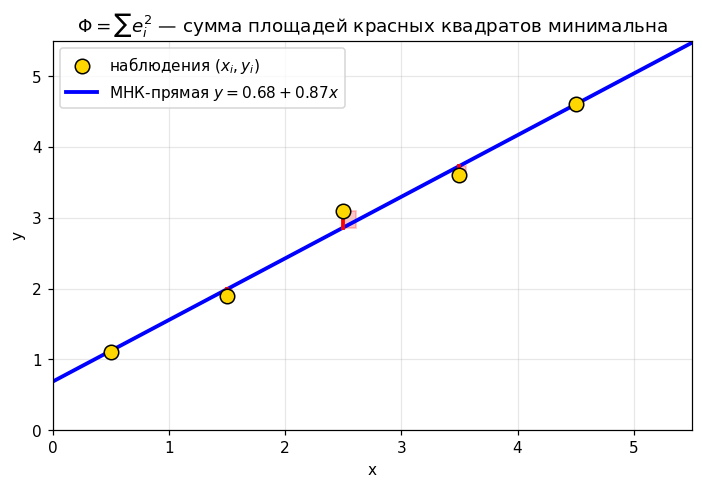

In [3]:
# Прямая, невязки и квадраты ошибок
XS = np.array([0.5, 1.5, 2.5, 3.5, 4.5])
YS = np.array([1.1, 1.9, 3.1, 3.6, 4.6])
AM = np.vstack([np.ones_like(XS), XS]).T
(a0_opt, a1_opt), *_ = np.linalg.lstsq(AM, YS, rcond=None)

def phi_lin(a0, a1):
    return float(np.sum((a0 + a1*XS - YS)**2))

print(f'МНК-решение: a0^={a0_opt:.4f}, a1^={a1_opt:.4f}, Phi_min={phi_lin(a0_opt,a1_opt):.4f}')

xg = np.linspace(0, 5.5, 300)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(XS, YS, s=90, c='gold', edgecolors='k', zorder=5, label='наблюдения $(x_i,y_i)$')
ax.plot(xg, a0_opt + a1_opt*xg, 'b-', lw=2.5, label=f'МНК-прямая $y={a0_opt:.2f}+{a1_opt:.2f}x$')
for x, y in zip(XS, YS):
    yp = a0_opt + a1_opt*x
    ax.plot([x, x], [yp, y], 'r-', lw=2.5)  # невязка e_i
    h = abs(y - yp)
    w = 0.45*h  # ширина квадрата пропорциональна |e_i| для наглядности
    ax.add_patch(Rectangle((x, min(yp, y)), w, h, facecolor='red', alpha=0.22, edgecolor='red', lw=1.2))
ax.set_xlim(0, 5.5); ax.set_ylim(0, 5.5)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title(r'$\Phi=\sum e_i^2$ — сумма площадей красных квадратов минимальна')
plt.show()

In [4]:
# Анимация: как Phi уменьшается при переходе к решению МНК
# Начальная (плохая) прямая -> оптимальная.
a0_start, a1_start = 2.5, 0.2
N = 70
fig, ax = plt.subplots(figsize=(7.5, 4.6))
plt.close(fig)
fig2, ax2 = plt.subplots(figsize=(7.5, 4.6))

def frame(k):
    ax2.clear()
    t = k/(N-1)
    a0 = a0_start + (a0_opt-a0_start)*t
    a1 = a1_start + (a1_opt-a1_start)*t
    ax2.scatter(XS, YS, s=90, c='gold', edgecolors='k', zorder=5)
    ax2.plot(xg, a0+a1*xg, 'b-', lw=2.5)
    for x, y in zip(XS, YS):
        yp = a0+a1*x
        ax2.plot([x,x],[yp,y],'r-',lw=2.2)
    ax2.set_xlim(0,5.5); ax2.set_ylim(0,5.5); ax2.grid(True,alpha=0.3)
    ax2.set_xlabel('x'); ax2.set_ylabel('y')
    ax2.set_title(f'$a_0={a0:.2f},\\ a_1={a1:.2f},\\ \\Phi={phi_lin(a0,a1):.2f}$')

ani = animation.FuncAnimation(fig2, frame, frames=N, interval=70)
plt.close(fig2)
HTML(ani.to_jshtml())

🎬 **Видео к этому разделу:** `LeastSquaresSquares.mp4`

In [15]:
Video('manim_mnk/LeastSquaresSquares.mp4', width=640, embed=True)

**Что видно:** красные отрезки — невязки $e_i$, квадраты — $e_i^2$. При движении прямой к $\hat a$ суммарная площадь монотонно падает. Это и есть $\Phi\to\min$.

---

## 3 Система нормальных уравнений
Берём частные производные по каждому $a_j$ и приравниваем к нулю:
$$
\begin{cases}
\dfrac{\partial \Phi}{\partial a_0} = 0 \\[6pt]
\dfrac{\partial \Phi}{\partial a_1} = 0 \\[6pt]
\dots \\[6pt]
\dfrac{\partial \Phi}{\partial a_k} = 0
\end{cases}
\implies
\begin{cases}
\sum_{i=1}^{n} \big( a_0 + a_1 x_{i1} + \dots + a_k x_{ik} - y_i \big) = 0 \\[6pt]
\sum_{i=1}^{n} x_{i1} \big( a_0 + a_1 x_{i1} + \dots + a_k x_{ik} - y_i \big) = 0 \\[6pt]
\dots \\[6pt]
\sum_{i=1}^{n} x_{ik} \big( a_0 + a_1 x_{i1} + \dots + a_k x_{ik} - y_i \big) = 0
\end{cases}
$$

> $\Phi$ — неотрицательная квадратичная функция («чаша», см. раздел про чашу ниже), поэтому условия $\nabla\Phi=0$ не только необходимы, но и достаточны для глобального минимума.

---

### 4 Три прямые, не имеющие общей точки
Пусть требуется найти две величины $x_1$ и $x_2$, связь между которыми задаётся **тремя** равенствами:
$$
\begin{cases}
x_1 + 2x_2 = 8.5 \\[4pt]
2x_1 + x_2 = 6.7 \\[4pt]
x_1 + 3x_2 = 11.1
\end{cases}

$$
> ⚠️ **Ситуация:** три прямые на плоскости. В общем случае они **не пересекаются в одной точке** — система переопределена и точного решения не имеет.

**Цель:** найти такие $x_1^*, x_2^*$, чтобы сумма квадратов отклонений от всех трёх уравнений была минимальной.

> 💡 Ниже — картинка и анимация. Красный треугольник — попарные пересечения («треугольник ошибок»). Пунктиры — перпендикуляры от текущей точки к прямым.

Попарные пересечения: [1.633 3.433] [3.3 2.6] [1.8 3.1]
Phi(X_OPT)= 0.1786


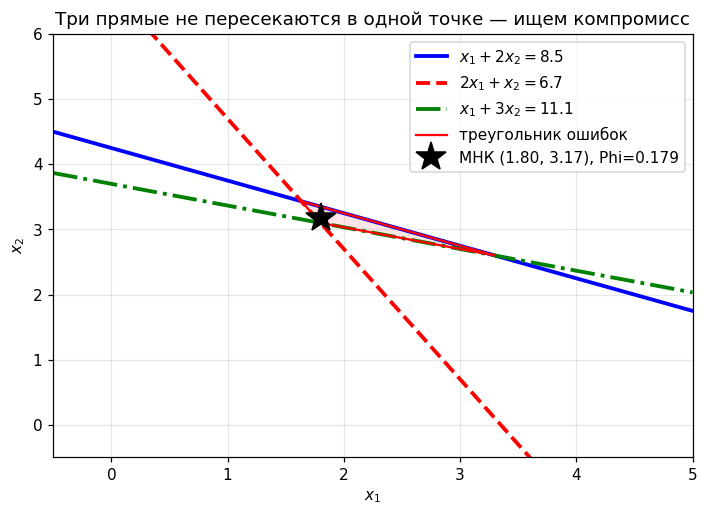

In [16]:
# Три прямые + треугольник ошибок + решение МНК
L1=(1.0,2.0,8.5); L2=(2.0,1.0,6.7); L3=(1.0,3.0,11.1)
X_OPT=np.array([1.8, 3.1714285714])
def resid2(a,b,c,p): return float(a*p[0]+b*p[1]-c)
def phi2(p): return float(sum(resid2(a,b,c,p)**2 for (a,b,c) in (L1,L2,L3)))
def inter(LA,LB):
    M=np.array([[LA[0],LA[1]],[LB[0],LB[1]]]); r=np.array([LA[2],LB[2]])
    return np.linalg.solve(M,r)
T12,T13,T23 = inter(L1,L2), inter(L1,L3), inter(L2,L3)
print('Попарные пересечения:', T12.round(3), T13.round(3), T23.round(3))
print('Phi(X_OPT)=', round(phi2(X_OPT),4))

x=np.linspace(-0.5,5,400)
f1=(L1[2]-L1[0]*x)/L1[1]; f2=(L2[2]-L2[0]*x)/L2[1]; f3=(L3[2]-L3[0]*x)/L3[1]
fig,ax=plt.subplots(figsize=(7.5,5))
ax.plot(x,f1,'b-',lw=2.5,label=r'$x_1+2x_2=8.5$')
ax.plot(x,f2,'r--',lw=2.5,label=r'$2x_1+x_2=6.7$')
ax.plot(x,f3,'g-.',lw=2.5,label=r'$x_1+3x_2=11.1$')
tri=np.array([T12,T13,T23,T12])
ax.fill(tri[:,0],tri[:,1],color='red',alpha=0.10)
ax.plot(tri[:,0],tri[:,1],'r-',lw=1.5,label='треугольник ошибок')
ax.plot(X_OPT[0],X_OPT[1],'*',ms=20,c='black',label=f'МНК (1.80, 3.17), Phi={phi2(X_OPT):.3f}')
ax.set_xlim(-0.5,5); ax.set_ylim(-0.5,6)
ax.set_xlabel(r'$x_1$'); ax.set_ylabel(r'$x_2$')
ax.grid(True,alpha=0.3); ax.legend()
ax.set_title('Три прямые не пересекаются в одной точке — ищем компромисс')
plt.show()

In [17]:
# Анимация: точка движется к решению МНК, перпендикуляры укорачиваются
def foot(a,b,c,p):
    d=(a*p[0]+b*p[1]-c)/(a*a+b*b)
    return np.array([p[0]-a*d, p[1]-b*d])
start=np.array([0.3,0.5]); NB=70
figB, axB = plt.subplots(figsize=(7.5,5))
plt.close(figB)
figB2, axB2 = plt.subplots(figsize=(7.5,5))
def frameB(k):
    axB2.clear()
    t=k/(NB-1); p=start+(X_OPT-start)*t
    axB2.plot(x,f1,'b-',lw=2); axB2.plot(x,f2,'r--',lw=2); axB2.plot(x,f3,'g-.',lw=2)
    axB2.fill(tri[:,0],tri[:,1],color='red',alpha=0.10)
    for (a,b,c),col in [(L1,'b'),(L2,'r'),(L3,'g')]:
        f=foot(a,b,c,p)
        axB2.plot([p[0],f[0]],[p[1],f[1]],color=col,ls=':',lw=2)
        axB2.plot(f[0],f[1],'o',color=col,ms=5)
    axB2.plot(p[0],p[1],'ro',ms=9)
    axB2.plot(X_OPT[0],X_OPT[1],'*',ms=16,c='k')
    axB2.set_xlim(-0.5,5); axB2.set_ylim(-0.5,6); axB2.grid(True,alpha=0.3)
    axB2.set_xlabel(r'$x_1$'); axB2.set_ylabel(r'$x_2$')
    axB2.set_title(f"p=({p[0]:.2f},{p[1]:.2f})  Phi={phi2(p):.2f}")
aniB=animation.FuncAnimation(figB2, frameB, frames=NB, interval=70)
plt.close(figB2)
HTML(aniB.to_jshtml())

🎬 **Видео к этому разделу:** `ThreeLinesLS.mp4`

In [18]:
Video('manim_mnk/ThreeLinesLS.mp4', width=640, embed=True)

---
#### 🎯 Минимизируемая функция
$$
\Phi(x_1, x_2) = (x_1 + 2x_2 - 8.5)^2 + (2x_1 + x_2 - 6.7)^2 + (x_1 + 3x_2 - 11.1)^2 \to \min
$$

---

#### 🛠️ Система нормальных уравнений
Берём частные производные и приравниваем к нулю:
$$
\begin{cases}
\dfrac{\partial \Phi}{\partial x_1} = 0 \\[6pt]
\dfrac{\partial \Phi}{\partial x_2} = 0
\end{cases}
\implies
\begin{cases}
6 x_1 + 7 x_2 = 33.0 \\[4pt]
7 x_1 + 14 x_2 = 57.0
\end{cases}
$$
Решая эту систему, получаем:
$$
x_1 \approx 1.800, \quad x_2 \approx 3.171
$$
Проверяем кодом (два способа должны совпасть): через явные нормальные уравнения и через `lstsq`.

---

In [19]:
# Проверка примера двумя способами
A=np.array([[1,2],[2,1],[1,3]],float); b=np.array([8.5,6.7,11.1])
# способ 1: нормальные уравнения вручную
Nmat=A.T@A; rhs=A.T@b
x_norm=np.linalg.solve(Nmat,rhs)
# способ 2: lstsq (устойчивее)
x_ls,*_=np.linalg.lstsq(A,b,rcond=None)
print('A^T A =\n',Nmat,'\nA^T b =',rhs)
print('решение нормальных уравнений:',x_norm.round(6))
print('lstsq:                         ',x_ls.round(6))
print('невязки r = Ax-b:',(A@x_ls-b).round(4),' Phi=',round(float(np.sum((A@x_ls-b)**2)),4))
print('ни одно уравнение точно не выполнено — и это нормально для МНК')

A^T A =
 [[ 6.  7.]
 [ 7. 14.]] 
A^T b = [33. 57.]
решение нормальных уравнений: [1.8      3.171429]
lstsq:                          [1.8      3.171429]
невязки r = Ax-b: [-0.3571  0.0714  0.2143]  Phi= 0.1786
ни одно уравнение точно не выполнено — и это нормально для МНК


## 5 Матричная форма
Обозначим:
- $\mathbf{a} = (a_0, a_1, \dots, a_k)^T$ — вектор неизвестных параметров (размер $k+1$)
- $\mathbf{y} = (y_1, y_2, \dots, y_n)^T$ — вектор наблюдений (размер $n$)
- $\mathbf{X}$ — **матрица плана** размера $n \times (k+1)$, первый столбец которой состоит из единиц:
$$
\mathbf{X} =
\begin{pmatrix}
1 & x_{11} & x_{12} & \dots & x_{1k} \\
1 & x_{21} & x_{22} & \dots & x_{2k} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & x_{n1} & x_{n2} & \dots & x_{nk}
\end{pmatrix}
$$
Тогда $\Phi(\mathbf{a})=\|\mathbf{Xa}-\mathbf{y}\|^2$ и
$$
\mathbf{X}^T \mathbf{X} \mathbf{a} = \mathbf{X}^T \mathbf{y}
$$
А её решение (если матрица $\mathbf{X}^T \mathbf{X}$ обратима):
$$
\mathbf{a} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}
$$

> 🧭 **Откуда берётся $X^TX$?** $\Phi=\sum r_i^2$, $r_i$ — $i$-я компонента вектора $\mathbf r=\mathbf{Xa}-\mathbf y$. $\partial\Phi/\partial a_j=2\sum_i X_{ij}r_i=0$ — это ровно $\mathbf X^T\mathbf r=0$, т.е. $\mathbf X^T(\mathbf{Xa}-\mathbf y)=0$.

> 🧭 **Геометрия (проекция):** столбец $\mathbf b=\mathbf y$ обычно **вне** подпространства $\mathrm{Col}(\mathbf X)$ (образа матрицы). МНК ищет ближайшую точку $\mathbf p=\mathbf{X\hat a}\in\mathrm{Col}(\mathbf X)$. Остаток $\mathbf e=\mathbf b-\mathbf p$ обязан быть **ортогонален** всему образу: $\mathbf X^T\mathbf e=0$. Это и есть нормальные уравнения. Ниже это показано в $\mathbb R^3$ на примере с целыми числами.

---

A^T e = [0. 0.] (нули => e ⊥ Col(A))
x^ = (A^T A)^{-1}A^T b = [1. 1.]


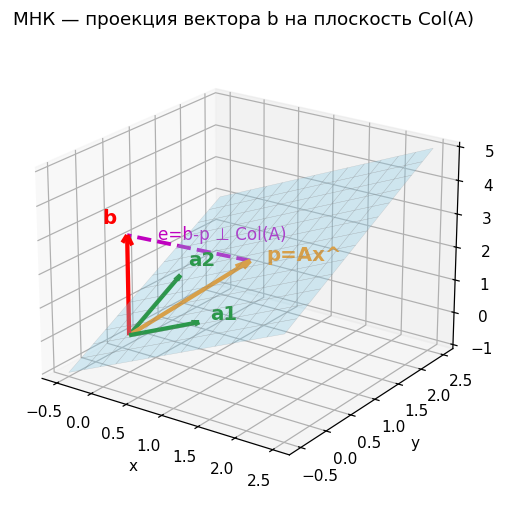

In [20]:
# МНК как проекция b на Col(A)
# A=[[1,0],[0,1],[1,1]] (столбцы a1,a2), b=(0,0,3). Col(A): плоскость z=x+y.
# Решение целое: x^=(1,1), p=(1,1,2), e=(-1,-1,1).
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (нужен для 3d)
A1=np.array([1.,0.,1.]); A2=np.array([0.,1.,1.]); Bv=np.array([0.,0.,3.])
Pv=np.array([1.,1.,2.]); Ev=Bv-Pv
print('A^T e =', (np.array([[1,0,1],[0,1,1]])@Ev).round(10), '(нули => e ⊥ Col(A))')
print('x^ = (A^T A)^{-1}A^T b =', (np.linalg.inv(np.array([[1,0,1],[0,1,1]])@np.array([[1,0],[0,1],[1,1]]))@np.array([[1,0,1],[0,1,1]])@Bv).round(6))

fig=plt.figure(figsize=(7.5,5.5))
ax=fig.add_subplot(111,projection='3d')
u=np.linspace(-0.5,2.5,14); vv=np.linspace(-0.5,2.5,14)
U,V=np.meshgrid(u,vv); W=U+V
ax.plot_surface(U,V,W,color='skyblue',alpha=0.32,edgecolor='gray',linewidth=0.25)
o=np.zeros(3)
for vec,col,lab,off in [(A1,'green','a1',(0.15,0,0.15)),(A2,'green','a2',(0,0.15,0.15)),(Bv,'red','b',(-0.35,0,0.15)),(Pv,'darkorange','p=Ax^',(0.15,0.1,0))]:
    ax.quiver(0,0,0,vec[0],vec[1],vec[2],color=col,length=1.0,arrow_length_ratio=0.09,lw=2.8)
    ax.text(vec[0]+off[0],vec[1]+off[1],vec[2]+off[2],lab,color=col,fontsize=13,weight='bold')
ax.plot([Pv[0],Bv[0]],[Pv[1],Bv[1]],[Pv[2],Bv[2]],'m--',lw=2.5)
ax.text((Pv[0]+Bv[0])/2-0.45,(Pv[1]+Bv[1])/2,(Pv[2]+Bv[2])/2,'e=b-p ⊥ Col(A)',color='m',fontsize=11)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('МНК — проекция вектора b на плоскость Col(A)')
ax.view_init(elev=22,azim=-55)
plt.show()

> **Как читать картинку C:** синяя плоскость — все достижимые $A\mathbf x$; красная стрелка $\mathbf b$ висит над ней; жёлтая $\mathbf p$ — её тень (проекция); малиновый пунктир $\mathbf e$ — перпендикуляр. Условие перпендикулярности $A^T\mathbf e=0$ — это и есть нормальные уравнения.

---

🎬 **Видео к этому разделу:** `LeastSquaresProjection.mp4`

In [21]:
Video('manim_mnk/LeastSquaresProjection.mp4', width=640, embed=True)

## 6 Развёрнутая форма системы
$$
\begin{pmatrix}
n & \sum x_{i1} & \dots & \sum x_{ik} \\[4pt]
\sum x_{i1} & \sum x_{i1}^2 & \dots & \sum x_{i1}x_{ik} \\[4pt]
\vdots & \vdots & \ddots & \vdots \\[4pt]
\sum x_{ik} & \sum x_{ik}x_{i1} & \dots & \sum x_{ik}^2
\end{pmatrix}
\begin{pmatrix} a_0 \\ a_1 \\ \vdots \\ a_k \end{pmatrix}
=
\begin{pmatrix} \sum y_i \\ \sum x_{i1} y_i \\ \vdots \\ \sum x_{ik} y_i \end{pmatrix}
$$
> 🧠 **Замечание:** если столбцы матрицы $\mathbf{X}$ **ортогональны** (их скалярные произведения равны нулю), то матрица $\mathbf{X}^T \mathbf{X}$ становится **диагональной**, и коэффициенты $a_j$ вычисляются независимо друг от друга — это самый устойчивый и быстрый случай.

**Демо:** сравним общий случай и ортогональные столбцы:

In [5]:
# Диагональный случай: столбцы X ортогональны -> X^T X диагональна
np.random.seed(0)
n=6
q,_=np.linalg.qr(np.random.randn(n,3))  # ортонормированные столбцы
Xo=q; yo=np.array([1,2,1,3,2,4],float)
Gt=Xo.T@Xo
print('X^T X при ортогональных столбцах:\n',Gt.round(6))
print('=> коэффициенты независимы: a_j=(x_j,y)/(x_j,x_j):',(Xo.T@yo).round(4))
print()
print('Для сравнения: cond(X^T X) обычной матрицы плана из примера выше:',round(np.linalg.cond(AM.T@AM),3))

X^T X при ортогональных столбцах:
 [[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]
=> коэффициенты независимы: a_j=(x_j,y)/(x_j,x_j): [-3.5873 -2.5892  2.956 ]

Для сравнения: cond(X^T X) обычной матрицы плана из примера выше: 40.757


## 7 Почему степенной базис плох: матрица Гильберта
Если искать многочлен $P_m(x)=c_0+c_1x+\dots+c_mx^m$ по непрерывному МНК на $[0,1]$, нормальная система — это **Гильберт** $H_{ij}=1/(i+j+1)$. Он заведомо невырожден, но его число обусловленности растёт катастрофически: $\mathrm{cond}(H_2)\approx20$, $\mathrm{cond}(H_6)\approx10^7$, $\mathrm{cond}(H_{10})\approx10^{13}$. Ошибки округления и погрешности интегралов в правой части умножаются на этот коэффициент — старшие коэффициенты «взрываются». В дискретном случае с равномерными узлами матрица дискретного случая при росте числа узлов стремится к Гильберту — те же проблемы.


In [22]:
# Рост обусловленности матрицы Гильберта
from scipy.linalg import hilbert
print(f"{'m':>3} {'размер':>7} {'cond(H)':>12}")
for m in [1,2,3,5,7,9,10]:
    H=hilbert(m+1)
    print(f'{m:>3} {m+1:>4}x{m+1:<3} {np.linalg.cond(H):>12.2e}')

  m  размер      cond(H)
  1    2x2       1.93e+01
  2    3x3       5.24e+02
  3    4x4       1.55e+04
  5    6x6       1.50e+07
  7    8x8       1.53e+10
  9   10x10      1.60e+13
 10   11x11      5.23e+14


старт Phi=78.3 -> финиш Phi=0.0830, МНК Phi=0.0830


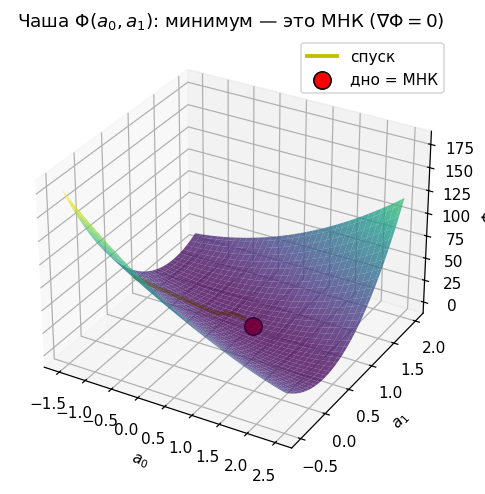

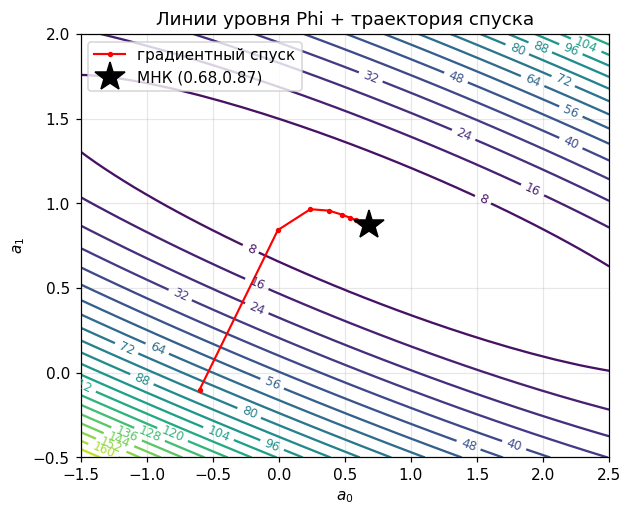

In [23]:
# Чаша Phi(a0,a1) + спуск
# Поверхность + линии уровня + траектория градиентного спуска к дну (МНК).
def phi2d(a0,a1): return float(np.sum((a0+a1*XS-YS)**2))
# спуск из (-0.6,-0.1), lr=0.02, 400 шагов
p=np.array([-0.6,-0.1]); traj=[]
for _ in range(400):
    traj.append((float(p[0]),float(p[1]),phi2d(*p)))
    r=AM@p-YS; g=2.0*(AM.T@r); p=p-0.02*g
traj=np.array(traj); trail=traj[::8]
print(f'старт Phi={traj[0,2]:.1f} -> финиш Phi={traj[-1,2]:.4f}, МНК Phi={phi2d(a0_opt,a1_opt):.4f}')

a0g=np.linspace(-1.5,2.5,70); a1g=np.linspace(-0.5,2.0,70)
A0,A1m=np.meshgrid(a0g,a1g)
Z=np.array([[phi2d(a0,a1) for a0 in a0g] for a1 in a1g])

fig=plt.figure(figsize=(8,5.2))
ax=fig.add_subplot(111,projection='3d')
ax.plot_surface(A0,A1m,Z,cmap='viridis',alpha=0.78,edgecolor='none')
ax.plot(trail[:,0],trail[:,1],trail[:,2]+0.8,'y-',lw=2.5,label='спуск')
ax.scatter([a0_opt],[a1_opt],[phi2d(a0_opt,a1_opt)],s=130,c='r',edgecolors='k',zorder=5,label='дно = МНК')
ax.set_xlabel('$a_0$'); ax.set_ylabel('$a_1$'); ax.set_zlabel(r'$\Phi$')
ax.set_title(r'Чаша $\Phi(a_0,a_1)$: минимум — это МНК ($\nabla\Phi=0$)')
ax.view_init(elev=30,azim=-60); ax.legend()
plt.show()

fig2,ax2=plt.subplots(figsize=(6.2,5))
cs=ax2.contour(A0,A1m,Z,levels=22)
ax2.clabel(cs,fmt='%.0f',fontsize=8)
ax2.plot(trail[:,0],trail[:,1],'r.-',ms=5,lw=1.4,label='градиентный спуск')
ax2.plot(a0_opt,a1_opt,'*',ms=20,c='k',label=f'МНК ({a0_opt:.2f},{a1_opt:.2f})')
ax2.set_xlabel('$a_0$'); ax2.set_ylabel('$a_1$')
ax2.set_title('Линии уровня Phi + траектория спуска')
ax2.legend(); ax2.grid(True,alpha=0.3)
plt.show()

> **Как читать вставку D:** $\Phi$ — выпуклая «чаша» (параболоид). Условие $\nabla\Phi=0$ — это дно чаши, т.е. нормальные уравнения $A^TAx=A^Tb$. Жёлтая траектория — градиентный спуск: шарик катится вниз и останавливается в точке МНК. Выпуклость гарантирует единственность минимума.

---

🎬 **Видео к этому разделу:** `LeastSquaresBowl.mp4`

In [24]:
Video('manim_mnk/LeastSquaresBowl.mp4', width=640, embed=True)

## 8 Вероятностный смысл МНК

До сих пор квадраты были геометрией («сумма площадей минимальна»). Теперь — статистика: квадраты появляются сами, если шум измерений гауссов.

**Модель.** Пусть наблюдения зашумлены независимыми одинаково распределёнными ошибками:
$$
y_i = a_0 + a_1 x_{i1} + \dots + a_k x_{ik} + \varepsilon_i, \qquad \varepsilon_i \sim N(0, \sigma^2).
$$
Векторно: $\mathbf{y} = \mathbf{Xa} + \boldsymbol{\varepsilon}$.

**Правдоподобие.** Плотность одного наблюдения — гауссиана с центром в $\mathbf{x}_i^T\mathbf{a}$:
$$
L(\mathbf{a}) = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{r_i^2}{2\sigma^2}\right), \qquad r_i = \mathbf{x}_i^T\mathbf{a} - y_i.
$$
Логарифмируем:
$$
\log L(\mathbf{a}) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{n} r_i^2.
$$
Первое слагаемое от $\mathbf{a}$ не зависит. Значит, **максимум правдоподобия по $\mathbf{a}$ — это ровно минимум суммы квадратов**. МНК-оценка совпадает с оценкой максимального правдоподобия, решение то же самое:
$$
\mathbf{X}^T\mathbf{X}\hat{\mathbf{a}} = \mathbf{X}^T\mathbf{y}.
$$


Ниже — проверка на синтетике: зашумляем известную прямую гауссианой, восстанавливаем МНК, смотрим остатки и доверительную полосу.

In [ ]:
# Демо: гауссов шум -> МНК = максимум правдоподобия
rng = np.random.default_rng(7)
n = 60
x = np.sort(rng.uniform(0, 5, n))
a0_true, a1_true, sigma_true = 0.7, 0.85, 0.35
y = a0_true + a1_true * x + rng.normal(0, sigma_true, n)

X = np.vstack([np.ones_like(x), x]).T
ahat, *_ = np.linalg.lstsq(X, y, rcond=None)
r = y - X @ ahat
p = X.shape[1]
RSS = float(r @ r)
sigma_hat = np.sqrt(RSS / (n - p))  # делим на n-p: поправка на оценённые параметры
Cov = sigma_hat ** 2 * np.linalg.inv(X.T @ X)
se = np.sqrt(np.diag(Cov))
print(f'истина: a0={a0_true} a1={a1_true} sigma={sigma_true}')
print(f'МНК:    a0={ahat[0]:.4f}+-{se[0]:.4f} a1={ahat[1]:.4f}+-{se[1]:.4f} sigma_hat={sigma_hat:.4f}')

# максимум правдоподобия вдоль среза a1: пик ровно в точке МНК
print('\nlog-правдоподобие (срез по a1):')
for a1 in [ahat[1] - 0.15, ahat[1] - 0.075, ahat[1], ahat[1] + 0.075, ahat[1] + 0.15]:
    ll = -n / 2 * np.log(2 * np.pi * sigma_hat ** 2) - np.sum((ahat[0] + a1 * x - y) ** 2) / (2 * sigma_hat ** 2)
    mark = '<- МНК' if abs(a1 - ahat[1]) < 1e-12 else ''
    print(f'  a1={a1:.4f} logL={ll:.3f} {mark}')

# доверительная полоса среднего отклика (~95%, t~2 при n-p=58)
t = 2.0
xg = np.linspace(0, 5, 200)
Xg = np.vstack([np.ones_like(xg), xg]).T
pred = Xg @ ahat
V = np.linalg.inv(X.T @ X)
se_mean = sigma_hat * np.sqrt(np.einsum('ij,jk,ik->i', Xg, V, Xg))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.scatter(x, y, s=18, c='gold', edgecolors='k', alpha=0.8, label='наблюдения')
ax1.plot(xg, a0_true + a1_true * xg, 'g--', lw=2, label='истина')
ax1.plot(xg, pred, 'b-', lw=2.5, label='МНК')
ax1.fill_between(xg, pred - t * se_mean, pred + t * se_mean, color='blue', alpha=0.15, label='дов. полоса ~95%')
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.grid(True, alpha=0.3); ax1.legend()
ax1.set_title('Гауссов шум: МНК восстанавливает прямую')
ax2.hist(r, bins=12, density=True, color='skyblue', edgecolor='k', alpha=0.8, label='остатки')
gg = np.linspace(-1.2, 1.2, 300)
ax2.plot(gg, 1 / (sigma_hat * np.sqrt(2 * np.pi)) * np.exp(-gg ** 2 / (2 * sigma_hat ** 2)), 'r-', lw=2.5, label='N(0, σ̂)')
ax2.set_xlabel('остаток'); ax2.set_ylabel('плотность'); ax2.grid(True, alpha=0.3); ax2.legend()
ax2.set_title('Остатки похожи на гауссиану — модель адекватна')
plt.show()